In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/iris.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

df['class'] = encoder.fit_transform(df['class'])

In [5]:
df = df[df['class'] != 0][['sepal_width', 'petal_length', 'class']]

In [7]:
df.head()

,sepal_width,petal_length,class
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


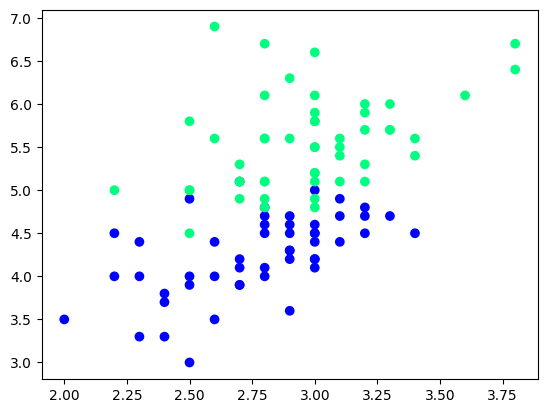

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.scatter(df['sepal_width'],df['petal_length'], c=df['class'], cmap='winter')

In [9]:
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [10]:
df_train

,sepal_width,petal_length,class
149,3.0,5.1,2
74,2.9,4.3,1
81,2.4,3.7,1
130,2.8,6.1,2
85,3.4,4.5,1
137,3.1,5.5,2
57,2.4,3.3,1
87,2.3,4.4,1
83,2.7,5.1,1
134,2.6,5.6,2


In [11]:
df_val

,sepal_width,petal_length,class
54,2.8,4.6,1
69,2.5,3.9,1
111,2.7,5.3,2
129,3.0,5.8,2
97,2.9,4.3,1


In [12]:
df_test

,sepal_width,petal_length,class
70,3.2,4.8,1
52,3.1,4.9,1
91,3.0,4.6,1
113,2.5,5.0,2
148,3.4,5.4,2


In [14]:
X_test = df_val.iloc[:,:2].values
y_test = df_val.iloc[:,-1].values

# Case 1 - Bagging

In [15]:
df_bag = df_train.sample(8, replace=True)
X = df_bag.iloc[:,:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,class
81,2.4,3.7,1
85,3.4,4.5,1
87,2.3,4.4,1
137,3.1,5.5,2
81,2.4,3.7,1
137,3.1,5.5,2
81,2.4,3.7,1
81,2.4,3.7,1


In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [22]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values,clf=clf,legend=2)
    y_pred = clf.predict(X_test)
    print('accuracy ->',accuracy_score(y_test, y_pred))

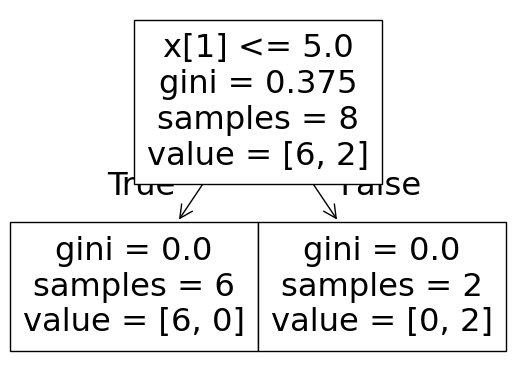

accuracy -> 1.0


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


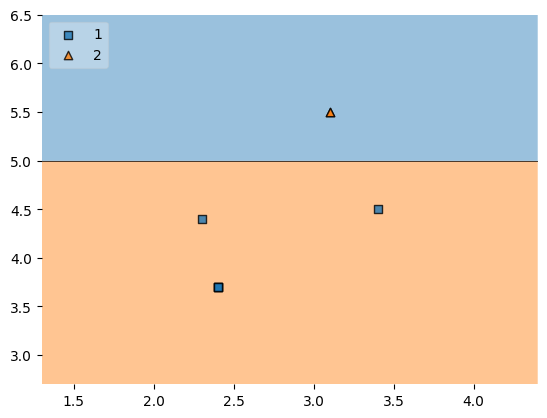

In [20]:
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

In [23]:
df_bag = df_train.sample(8, replace=True)
X = df_bag.iloc[:,:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,class
85,3.4,4.5,1
83,2.7,5.1,1
74,2.9,4.3,1
87,2.3,4.4,1
83,2.7,5.1,1
87,2.3,4.4,1
74,2.9,4.3,1
137,3.1,5.5,2


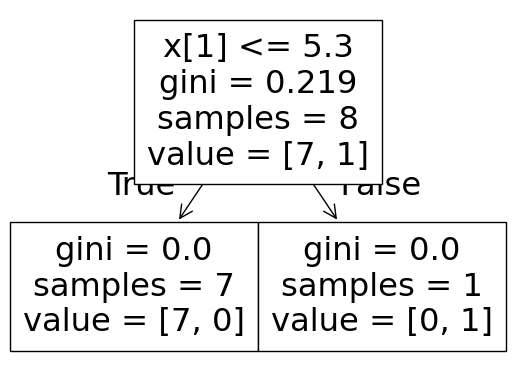

accuracy -> 1.0


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


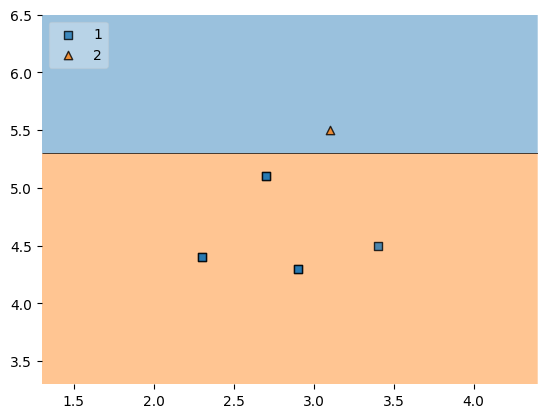

In [24]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [25]:
df_bag = df_train.sample(8, replace=True)
X = df_bag.iloc[:,:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,class
130,2.8,6.1,2
137,3.1,5.5,2
81,2.4,3.7,1
87,2.3,4.4,1
74,2.9,4.3,1
149,3.0,5.1,2
57,2.4,3.3,1
137,3.1,5.5,2


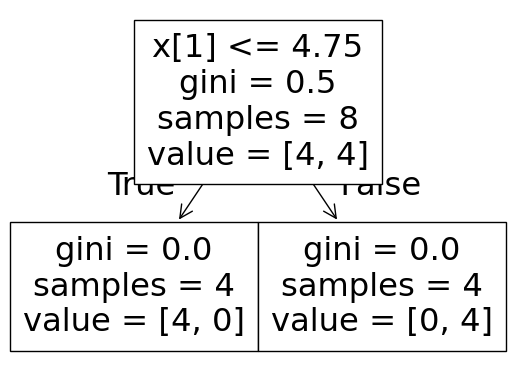

accuracy -> 1.0


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


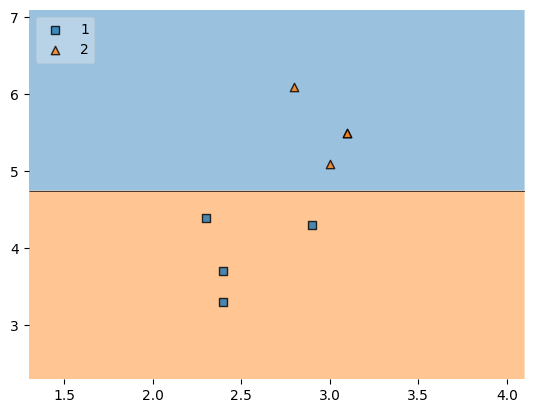

In [26]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

# Predict

In [27]:
df_test

,sepal_width,petal_length,class
70,3.2,4.8,1
52,3.1,4.9,1
91,3.0,4.6,1
113,2.5,5.0,2
148,3.4,5.4,2


In [29]:
print('Predictor 1',dt_bag1.predict(np.array([3.2, 4.8]).reshape(1,2)))
print('Predictor 2',dt_bag2.predict(np.array([3.2, 4.8]).reshape(1,2)))
print('Predictor 3',dt_bag3.predict(np.array([3.2, 4.8]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [1]
Predictor 3 [2]


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
